# 02 - Feature engineering, model selection and MLflow tracking
Full pipeline: `FeatureEngineer -> ColumnTransformer(impute+scale | impute+one-hot) -> classifier`.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
%matplotlib inline
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, mlflow, json
from src.train import setup_mlflow, MODEL_ZOO
from src.config import METRICS_PATH
setup_mlflow()

2026/10/18 11:19:03 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/10/18 11:19:03 INFO mlflow.store.db.utils: Updating database tables


'sqlite:////home/claude/heart-disease-mlops/mlflow.db'

## Candidate models and hyper-parameter grids

In [2]:
for name, (est, grid) in MODEL_ZOO.items():
    print(name, grid)

logistic_regression {'clf__C': [0.01, 0.1, 1, 10], 'clf__class_weight': [None, 'balanced']}
random_forest {'clf__n_estimators': [200, 400], 'clf__max_depth': [3, 5, None], 'clf__min_samples_leaf': [1, 3]}
gradient_boosting {'clf__n_estimators': [100, 200], 'clf__learning_rate': [0.05, 0.1], 'clf__max_depth': [2, 3]}


## Train (writes everything to MLflow)
Selection uses 5-fold stratified CV ROC-AUC on the 80% training split; the 20% hold-out is only used to report final metrics.

In [3]:
from src.train import main
main()

MLflow tracking URI: sqlite:////home/claude/heart-disease-mlops/mlflow.db


2026/10/18 11:19:07 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


logistic_regression    cv_auc=0.902 test_auc=0.966 test_acc=0.885


2026/10/18 11:19:37 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


random_forest          cv_auc=0.902 test_auc=0.957 test_acc=0.836


2026/10/18 11:19:49 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


2026/10/18 11:19:52 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


gradient_boosting      cv_auc=0.878 test_auc=0.959 test_acc=0.902
Selected model: logistic_regression


Saved /home/claude/heart-disease-mlops/models/heart_pipeline.joblib  (50s)


Successfully registered model 'heart-disease-classifier'.
Created version '1' of model 'heart-disease-classifier'.


## Compare runs

In [4]:
runs = mlflow.search_runs(experiment_names=['heart-disease-risk'], filter_string="tags.stage = 'model-selection'")
cols = ['tags.mlflow.runName','metrics.cv_roc_auc','metrics.cv_accuracy','metrics.cv_precision','metrics.cv_recall','metrics.test_roc_auc','metrics.test_accuracy','metrics.test_precision','metrics.test_recall']
runs[cols].round(3).sort_values('metrics.cv_roc_auc', ascending=False)

,tags.mlflow.runName,metrics.cv_roc_auc,metrics.cv_accuracy,metrics.cv_precision,metrics.cv_recall,metrics.test_roc_auc,metrics.test_accuracy,metrics.test_precision,metrics.test_recall
1,random_forest,0.902,0.818,0.843,0.755,0.957,0.836,0.800,0.857
2,logistic_regression,0.902,0.847,0.877,0.783,0.966,0.885,0.839,0.929
0,gradient_boosting,0.878,0.822,0.829,0.783,0.959,0.902,0.867,0.929


In [5]:
meta = json.loads(METRICS_PATH.read_text()); print('Selected:', meta['selected_model'])

Selected: logistic_regression


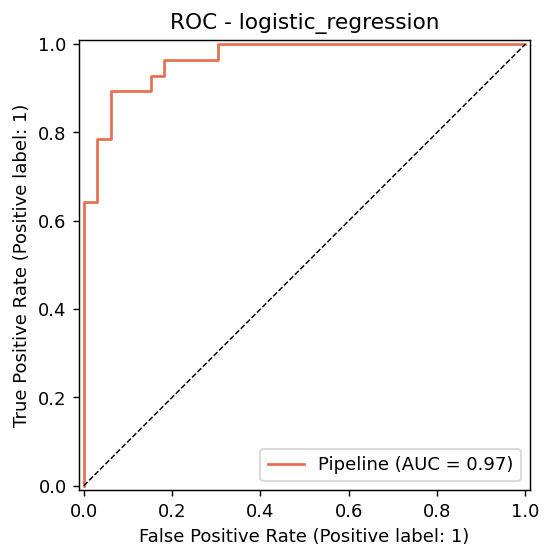

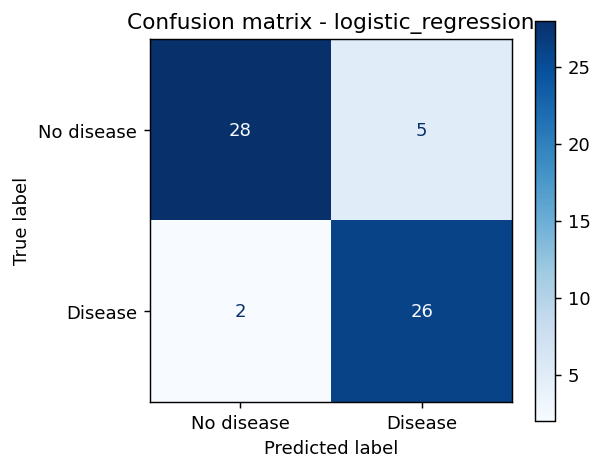

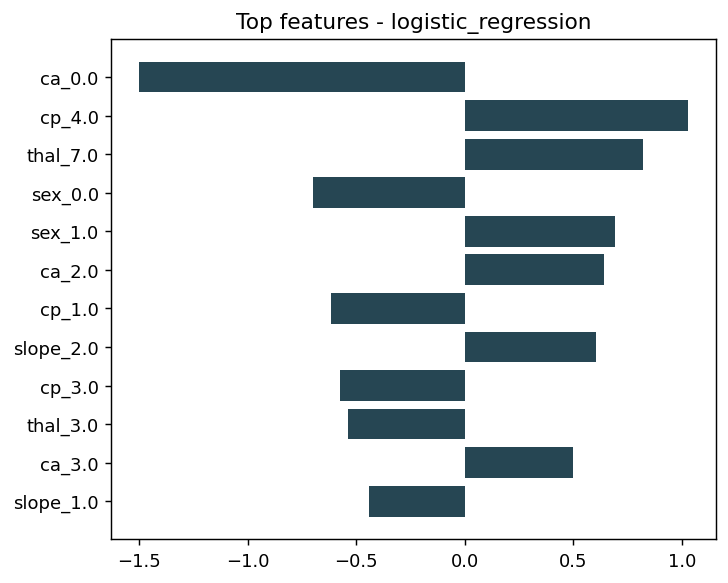

In [6]:
from IPython.display import Image, display
for f in ['roc_logistic_regression','cm_logistic_regression','importance_logistic_regression']:
    display(Image(str(ROOT/'reports'/'figures'/f'{f}.png'), width=420))